# AI-Based Anomaly Detection and Intelligent Monitoring of Chiller Operating Data
**Case study 11 – Impact of condenser temperature & load on efficiency**

**Track:** Explainability, benchmarking and robustness  |  **Method:** Local Outlier Factor (LOF) + local feature perturbation
**Preprocessing:** imputation, scaling, neighbourhood selection  |  **Evaluation:** explanation stability, local case review

**Research question.** Can local explanations clarify *why* individual observations receive high anomaly scores?

**Important.** A flagged observation is only a *potential* anomaly. Nothing in this notebook confirms an equipment fault;
that needs independent evidence (maintenance logs, inspection, trend review by an engineer).

Notebook layout: 1 Setup → 2 Load & audit → 3 Cleaning rules → 4 Features → 5 Chronological split → 6 Train-only preprocessing →
7 Neighbourhood (k) selection → 8 Final LOF → 9 Case study (condenser T & load vs. efficiency) → 10 Local perturbation explainer →
11 Evaluation (stability, plausibility, injection test) → 12 Local case review → 13 Export.

In [1]:
import json, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import LocalOutlierFactor
warnings.filterwarnings("ignore")

SEED = 42
rng_global = np.random.default_rng(SEED)
DATA = Path("Analyse_Chillers_AI_Course.xls")          # raw file supplied by the instructor
# chronological split boundaries (whole days): train 11–15 Mar, validation 16–17 Mar, test 18–20 Mar
TRAIN_END, VAL_END = pd.Timestamp("2026-03-16 00:00"), pd.Timestamp("2026-03-18 00:00")
OUT = Path("outputs"); (OUT/"figures").mkdir(parents=True, exist_ok=True); (OUT/"tables").mkdir(parents=True, exist_ok=True)

# plotting style: black-and-white print version (grayscale; groups are told apart by marker, line style and hatching)
C = dict(blue="#1a1a1a", orange="#7a7a7a", aqua="#a8a8a8", yellow="#c8c8c8", magenta="#8a8a8a", violet="#4a4a4a", ink="#000000", mute="#555555", grid="#dddddd")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": C["mute"], "axes.labelcolor": C["ink"], "text.color": C["ink"], "axes.grid": True,
                     "grid.color": C["grid"], "grid.linewidth": .6, "axes.axisbelow": True, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "legend.frameon": False})
def savefig(name): plt.savefig(OUT/"figures"/name, bbox_inches="tight"); plt.show()

## 1–2. Load the raw log and audit it
The sheet has two title rows, then a header row. Each record is one hourly log entry for one chiller (each chiller has two compressors).
Rows are in **descending** time order, so the first job is to build a real timestamp and sort chronologically.

In [2]:
SHORT = ['sl','tag','date','time','evap_in','evap_out','cond_in','cond_out','load1','load2','amp1','amp2','dis_t1','dis_t2','dis_p1','dis_p2',
 'suc_t','suc_p','liftT1','liftT2','liftP1','liftP2','hrs1','hrs2','suc_sat','suc_sh','evap_app','dis_sat1','dis_sat2','dis_sh1','dis_sh2',
 'cond_app1','cond_app2','liq_t1','liq_t2','oil_t','vfd1','vfd2','exv_dp1','exv_dp2','exv_out1','vR','vY','vB','pp_suc','pp_dis','pp_iR','pp_iY','pp_iB',
 'cp_suc','cp_dis','cp_iR','cp_iY','cp_iB','ct1R','ct1Y','ct1B','ct2R','ct2Y','ct2B']
raw = pd.read_excel(DATA, header=2)
assert len(SHORT) == raw.shape[1]
long_names = dict(zip(SHORT, raw.columns))
raw.columns = SHORT
raw["ts"] = pd.to_datetime(raw["date"].dt.strftime("%Y-%m-%d") + " " + raw["time"].astype(str))
raw = raw.sort_values(["ts", "tag"]).reset_index(drop=True)
num_cols = [c for c in SHORT if c not in ("sl","tag","date","time")]
print("records:", len(raw), "| chillers:", raw.tag.nunique(), "| span:", raw.ts.min(), "→", raw.ts.max())
print("blank cells:", int(raw[num_cols].isna().sum().sum()), "| duplicate (chiller, timestamp):", int(raw.duplicated(["tag","ts"]).sum()))

records: 522 | chillers: 5 | span: 2026-03-11 00:00:00 → 2026-03-20 08:00:00
blank cells: 0 | duplicate (chiller, timestamp): 0


In [3]:
# Timestamp continuity per chiller: hourly cadence with gaps (chillers are rotated on/off duty, so gaps are expected, not errors)
gap_rows = []
for tag, g in raw.groupby("tag"):
    d = g.ts.diff().dropna()
    runs = (d > pd.Timedelta(hours=1)).sum() + 1
    gap_rows.append(dict(chiller=tag, records=len(g), first=g.ts.min(), last=g.ts.max(), hourly_steps=int((d == pd.Timedelta(hours=1)).sum()),
                         gaps_gt_1h=int((d > pd.Timedelta(hours=1)).sum()), longest_gap_h=d.max() / pd.Timedelta(hours=1), contiguous_runs=int(runs)))
continuity = pd.DataFrame(gap_rows); display(continuity)
continuity.to_csv(OUT/"tables"/"timestamp_continuity.csv", index=False)

,chiller,records,first,last,hourly_steps,gaps_gt_1h,longest_gap_h,contiguous_runs
0,Chiller - 1,96,2026-03-11 00:00:00,2026-03-20 08:00:00,91,4,113.0,5
1,Chiller - 2,86,2026-03-11 10:00:00,2026-03-15 18:00:00,83,2,17.0,3
2,Chiller - 3,120,2026-03-12 08:00:00,2026-03-19 18:00:00,114,5,22.0,6
3,Chiller - 4,131,2026-03-11 09:00:00,2026-03-19 17:00:00,123,7,43.0,8
4,Chiller - 5,89,2026-03-11 03:00:00,2026-03-20 08:00:00,76,12,42.0,13


In [4]:
# Physical identities hidden in the logged columns (they hold on most rows; median residual is 0). They tell us which columns are *derived* (redundant)
# and give us an independent test for typing errors.
ident = {
 "lift pressure = discharge P - suction P (comp1)": (raw.liftP1, raw.dis_p1 - raw.suc_p),
 "lift temperature = discharge T - suction T (comp1)": (raw.liftT1, raw.dis_t1 - raw.suc_t),
 "condenser approach = discharge sat. T - cond. water out (comp1)": (raw.cond_app1, raw.dis_sat1 - raw.cond_out),
 "evaporator approach = evap. water out - suction sat. T": (raw.evap_app, raw.evap_out - raw.suc_sat),
 "discharge superheat = discharge T - discharge sat. T (comp1)": (raw.dis_sh1, raw.dis_t1 - raw.dis_sat1),
 "suction superheat = suction T - suction sat. T": (raw.suc_sh, raw.suc_t - raw.suc_sat),
}
rows = [dict(identity=k, share_within_0p25=float(((a - b).abs() <= 0.25).mean()), median_abs_residual=float((a - b).abs().median())) for k, (a, b) in ident.items()]
for k in (1, 2):
    ratio = (raw[f"amp{k}"] / raw[f"load{k}"]).replace([np.inf], np.nan)
    med = ratio.median()
    rows.append(dict(identity=f"motor current / running load% is constant (comp{k}, median {med:.3f} A per %)",
                     share_within_0p25=float((ratio.sub(med).abs() / med < 0.05).mean()), median_abs_residual=float(ratio.sub(med).abs().median())))
identity_tbl = pd.DataFrame(rows); display(identity_tbl.round(3)); identity_tbl.to_csv(OUT/"tables"/"identity_checks.csv", index=False)
print("→ Load% is just motor current / full-load amps, and lift/approach/superheat columns are differences of other columns."
      " They are redundant, so only independent measurements go into the model.")

,identity,share_within_0p25,median_abs_residual
0,lift pressure = discharge P - suction P (comp1),0.983,0.000
1,lift temperature = discharge T - suction T (co...,0.893,0.000
2,condenser approach = discharge sat. T - cond. ...,0.889,0.000
3,evaporator approach = evap. water out - suctio...,0.787,0.000
4,discharge superheat = discharge T - discharge ...,0.826,0.000
5,suction superheat = suction T - suction sat. T,0.761,0.000
6,motor current / running load% is constant (com...,0.987,0.007
7,motor current / running load% is constant (com...,0.983,0.007


→ Load% is just motor current / full-load amps, and lift/approach/superheat columns are differences of other columns. They are redundant, so only independent measurements go into the model.


## 3. Cleaning rules (no fitting involved)
The sheet has **no blank cells**, but bad values are hidden as numbers: 2196 A motor current, 631 °C liquid temperature,
40.8 V phase voltage, 85 °C condenser outlet, run-hour counters that jump from 11 000 to 1 179, etc.
Decisions:
1. **Physically implausible value** (outside an engineering range, usually a missing decimal / digit slip) → set to NaN and later imputed. Every cell is logged.
2. **Compressor off** (running load = 0 %): the compressor's own variables are legitimately 0. This is an *operating state*, not a sensor fault.
   These rows are not scored by LOF (a different regime, handled by a rule) and are reported separately.
3. **Run-hour counters** are cumulative meters, not operating conditions: used only for a monotonicity audit and excluded from features.
4. **Condenser-pump pressures** read 0.0 on about 5 % of rows while pump current is normal (gauge not logged) – excluded from features.
5. **Load vs current mismatch** (one row: load 5.7 % with 129 A): current is the primary measurement; load is rebuilt as current / A-per-% (train median).

In [5]:
RANGES = dict(evap_in=(4,16), evap_out=(4,12), cond_in=(20,40), cond_out=(20,45), load1=(0,105), load2=(0,105), amp1=(0,260), amp2=(0,260),
  dis_t1=(30,80), dis_t2=(30,80), dis_p1=(3,15), dis_p2=(3,15), suc_t=(0,15), suc_p=(1.5,4), liftT1=(20,60), liftT2=(20,60), liftP1=(2,9), liftP2=(2,9),
  suc_sat=(0,15), suc_sh=(0,10), evap_app=(0,12), dis_sat1=(25,50), dis_sat2=(25,50), dis_sh1=(3,25), dis_sh2=(3,25), cond_app1=(0,8), cond_app2=(0,8),
  liq_t1=(20,45), liq_t2=(20,45), oil_t=(30,70), vfd1=(20,100.5), vfd2=(20,100.5), exv_dp1=(2,8), exv_dp2=(2,8), exv_out1=(0,100.5),
  vR=(380,440), vY=(380,440), vB=(380,440), pp_suc=(3,8), pp_dis=(5,10), pp_iR=(50,90), pp_iY=(50,90), pp_iB=(50,90),
  cp_iR=(40,80), cp_iY=(40,80), cp_iB=(40,80), ct1R=(5,40), ct1Y=(5,40), ct1B=(5,40), ct2R=(5,40), ct2Y=(5,40), ct2B=(5,40))
COMP1 = ['load1','amp1','dis_t1','dis_p1','liftT1','liftP1','dis_sat1','dis_sh1','cond_app1','liq_t1','vfd1','exv_dp1','exv_out1']
COMP2 = ['load2','amp2','dis_t2','dis_p2','liftT2','liftP2','dis_sat2','dis_sh2','cond_app2','liq_t2','vfd2','exv_dp2']

comp_off = (raw.load1 == 0) | (raw.load2 == 0)                              # structural state, not a fault
fan2_off = (raw[['ct2R','ct2Y','ct2B']] == 0).all(axis=1)                    # cooling-tower fan 2 stopped (valid state)
clean = raw.copy(); log = []
for col, (lo, hi) in RANGES.items():
    bad = ((raw[col] < lo) | (raw[col] > hi)) & ~comp_off
    if col.startswith("ct2"): bad &= ~fan2_off
    for i in raw.index[bad]:
        log.append(dict(sl=raw.sl[i], chiller=raw.tag[i], ts=raw.ts[i], variable=col, value=raw.loc[i, col], allowed=f"{lo}–{hi}"))
    clean.loc[bad, col] = np.nan
inval = pd.DataFrame(log); inval.to_csv(OUT/"tables"/"invalid_cells_log.csv", index=False)
print(f"invalid cells set to NaN: {len(inval)}  | rows affected: {inval.sl.nunique()}  | compressor-off rows (not scored): {int(comp_off.sum())}  | fan-2-off rows: {int(fan2_off.sum())}")
display(inval.groupby("variable").size().sort_values(ascending=False).rename("invalid cells").to_frame().T)
display(inval.sort_values("value", key=lambda s: -(s - s.median()).abs()).head(12))

# run-hour counters: monotone non-decreasing per chiller and compressor?
hrs = []
for tag, g in raw.groupby("tag"):
    for c in ("hrs1", "hrs2"):
        d = g[c].diff().dropna(); hrs.append(dict(chiller=tag, counter=c, decreases=int((d < 0).sum()), min=g[c].min(), max=g[c].max()))
hrs = pd.DataFrame(hrs); display(hrs); hrs.to_csv(OUT/"tables"/"runhour_audit.csv", index=False)

invalid cells set to NaN: 28  | rows affected: 21  | compressor-off rows (not scored): 5  | fan-2-off rows: 2


variable,amp1,ct1B,cond_out,dis_t1,dis_sat2,ct1R,dis_p2,liftT2,liq_t1,cond_in,amp2,dis_p1,cp_iY,dis_t2,evap_app,liftP2,evap_in,vR,vfd2
invalid cells,2,2,2,2,2,2,2,2,2,1,1,1,1,1,1,1,1,1,1


,sl,chiller,ts,variable,value,allowed
4,475,Chiller - 2,2026-03-11 19:00:00,amp1,2196.0,0–260
6,195,Chiller - 4,2026-03-16 17:00:00,amp2,2106.0,0–260
5,460,Chiller - 4,2026-03-12 02:00:00,amp1,1350.0,0–260
20,297,Chiller - 3,2026-03-14 18:00:00,liq_t1,631.1,20–45
14,391,Chiller - 3,2026-03-13 05:00:00,liftT2,415.0,20–60
19,441,Chiller - 3,2026-03-12 11:00:00,liq_t1,329.0,20–45
18,73,Chiller - 1,2026-03-18 18:00:00,dis_sat2,322.0,25–50
8,213,Chiller - 4,2026-03-16 11:00:00,dis_t1,213.9,30–80
24,273,Chiller - 2,2026-03-15 08:00:00,ct1R,187.0,5–40
25,110,Chiller - 4,2026-03-18 06:00:00,ct1R,145.0,5–40


,chiller,counter,decreases,min,max
0,Chiller - 1,hrs1,0,10798,10891
1,Chiller - 1,hrs2,1,10671,40715
2,Chiller - 2,hrs1,0,11403,11487
3,Chiller - 2,hrs2,1,1232,11238
4,Chiller - 3,hrs1,2,1179,11752
5,Chiller - 3,hrs2,3,1199,11742
6,Chiller - 4,hrs1,1,11925,12055
7,Chiller - 4,hrs2,1,11209,11337
8,Chiller - 5,hrs1,0,11676,11760
9,Chiller - 5,hrs2,1,11689,11776


In [6]:
# Load ↔ current consistency (A per % load is a motor property; estimated on training rows where both are in range)
ok = ~comp_off
train_rows = ok & (raw.ts < TRAIN_END)                    # constant estimated on training rows only
apl = {k: float((clean.loc[train_rows, f"amp{k}"] / clean.loc[train_rows, f"load{k}"]).median()) for k in (1, 2)}
print("A per % load:", apl)
n_fix = 0
for k in (1, 2):
    expected = clean[f"amp{k}"] / apl[k]
    mism = ok & clean[f"amp{k}"].notna() & clean[f"load{k}"].notna() & ((clean[f"load{k}"] - expected).abs() > 8)
    n_fix += int(mism.sum()); clean.loc[mism, f"load{k}"] = expected[mism]
    miss = ok & clean[f"load{k}"].isna() & clean[f"amp{k}"].notna(); clean.loc[miss, f"load{k}"] = expected[miss]
print("load values rebuilt from current:", n_fix)

A per % load: {1: 2.252483039348711, 2: 2.1525773195876288}
load values rebuilt from current: 6


## 4. Feature construction
One row = one chiller (two compressors) at one hour. Features are **independent measurements or physically meaningful differences**
(not columns that are exact differences of other columns). Groups are used later for group-level explanations.
* *Condenser side* – condenser water inlet temperature, water temperature rise, condensing (discharge saturation) temperature, sub-cooling, tower fans, condenser pump.
* *Load & capacity control* – running load of each compressor, VFD output, EXV opening.
* *Evaporator side* – chilled-water outlet temperature and rise, evaporating (suction saturation) temperature, suction superheat, primary pump.
* *Compressor / refrigerant circuit* – discharge superheat, EXV differential pressure, oil temperature.
* *Electrical supply* – mean phase voltage.

In [7]:
def phase_mean(df, cols): return df[cols].mean(axis=1, skipna=True)         # tolerates one bad phase reading

def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["cond_in"] = d.cond_in;                       f["cond_dT"] = d.cond_out - d.cond_in
    f["dis_sat1"] = d.dis_sat1;                     f["dis_sat2"] = d.dis_sat2
    f["subcool1"] = d.dis_sat1 - d.liq_t1;          f["subcool2"] = d.dis_sat2 - d.liq_t2
    f["tower_I"] = phase_mean(d, ['ct1R','ct1Y','ct1B']) + phase_mean(d, ['ct2R','ct2Y','ct2B'])
    f["condpump_I"] = phase_mean(d, ['cp_iR','cp_iY','cp_iB'])
    f["load1"] = d.load1;  f["load2"] = d.load2;    f["vfd1"] = d.vfd1;  f["vfd2"] = d.vfd2;  f["exv_out1"] = d.exv_out1
    f["evap_out"] = d.evap_out;                     f["evap_dT"] = d.evap_in - d.evap_out
    f["suc_sat"] = d.suc_sat;                       f["suc_sh"] = d.suc_sh;  f["primpump_I"] = phase_mean(d, ['pp_iR','pp_iY','pp_iB'])
    f["dis_sh1"] = d.dis_sh1;  f["dis_sh2"] = d.dis_sh2;  f["exv_dp1"] = d.exv_dp1;  f["exv_dp2"] = d.exv_dp2;  f["oil_t"] = d.oil_t
    f["volt"] = phase_mean(d, ['vR','vY','vB'])
    return f

GROUPS_ALL = {
 "Condenser side":        ["cond_in","cond_dT","dis_sat1","dis_sat2","subcool1","subcool2","tower_I","condpump_I"],
 "Load & capacity ctrl":  ["load1","load2","vfd1","vfd2","exv_out1"],
 "Evaporator side":       ["evap_out","evap_dT","suc_sat","suc_sh","primpump_I"],
 "Compressor / refrig.":  ["dis_sh1","dis_sh2","exv_dp1","exv_dp2","oil_t"],
 "Electrical supply":     ["volt"]}
LABELS = {"cond_in":"Cond. water in T","cond_dT":"Cond. water ΔT","dis_sat1":"Condensing T C1","dis_sat2":"Condensing T C2","subcool1":"Sub-cooling C1","subcool2":"Sub-cooling C2",
 "tower_I":"Tower fan current","condpump_I":"Cond. pump current","load1":"Load C1","load2":"Load C2","vfd1":"VFD out C1","vfd2":"VFD out C2","exv_out1":"EXV output",
 "evap_out":"Chilled water out T","evap_dT":"Chilled water ΔT","suc_sat":"Evaporating T","suc_sh":"Suction superheat","primpump_I":"Primary pump current",
 "dis_sh1":"Disch. superheat C1","dis_sh2":"Disch. superheat C2","exv_dp1":"EXV ΔP C1","exv_dp2":"EXV ΔP C2","oil_t":"Oil temperature","volt":"Supply voltage"}

feat_raw = build_features(clean)            # NaN where a raw cell was invalid
meta = raw[["sl","tag","ts"]].copy()
meta["comp_off"] = comp_off.values
meta["split"] = np.where(meta.ts < TRAIN_END, "train", np.where(meta.ts < VAL_END, "val", "test"))
model_mask = ~meta.comp_off                  # rows scored by LOF (both compressors running)
print(meta.groupby(["split", "comp_off"]).size().unstack(fill_value=0))

comp_off  False  True 
split                 
test        120      0
train       282      5
val         115      0


## 5. Chronological split
Whole-day blocks, no shuffling: **train 11–15 Mar**, **validation 16–17 Mar** (used only to choose k), **test 18–20 Mar** (held out).
Every statistic below (medians for imputation, scaling constants, correlation pruning, thresholds) is computed on the training block only.

In [8]:
split_tbl = meta.groupby("split").agg(rows=("sl", "size"), start=("ts", "min"), end=("ts", "max"), comp_off_rows=("comp_off", "sum")).loc[["train", "val", "test"]]
split_tbl["scored_rows"] = meta[model_mask].groupby("split").size()
display(split_tbl); split_tbl.to_csv(OUT/"tables"/"split_summary.csv")
display(pd.crosstab(meta.split, meta.tag).loc[["train","val","test"]])

,rows,start,end,comp_off_rows,scored_rows
split,,,,,
train,287,2026-03-11,2026-03-15 23:00:00,5,282
val,115,2026-03-16,2026-03-17 23:00:00,0,115
test,120,2026-03-18,2026-03-20 08:00:00,0,120


tag,Chiller - 1,Chiller - 2,Chiller - 3,Chiller - 4,Chiller - 5
split,,,,,
train,18,86,65,61,57
val,34,0,32,35,14
test,44,0,23,35,18


## 6. Train-only preprocessing: imputation → pruning → scaling
* **Imputation** (cells set to NaN in section 3): (i) causal forward-fill from the same chiller's previous record if it is ≤ 3 h earlier (uses past only);
  (ii) otherwise the **training median for that chiller** (global training median if the chiller has no training rows).
* **Redundancy pruning**: drop the later of any pair with training |Spearman ρ| > 0.90 (feature order = domain priority). No PCA, to keep explanations in physical units.
* **Scaling**: `RobustScaler` (median / IQR) fitted on training rows, because LOF is distance-based and the training block still contains rare extremes.

In [9]:
feat_cols = list(feat_raw.columns)
isna_mask = feat_raw.isna()                                         # remember what was imputed
F = feat_raw.copy()
# (i) causal forward fill within chiller, max 3 h old
for tag, idx in meta.groupby("tag").groups.items():
    sub = meta.loc[idx].sort_values("ts"); fs = F.loc[sub.index]
    age_ok = sub.ts.diff().dt.total_seconds().div(3600).le(3)
    filled = fs.ffill(limit=3)
    for c in feat_cols:
        m = fs[c].isna() & filled[c].notna() & age_ok.reindex(fs.index, fill_value=False)
        F.loc[m[m].index, c] = filled.loc[m[m].index, c]
# (ii) train-only per-chiller median, then global train median
tr_idx = meta.index[(meta.split == "train") & model_mask]
glob_med = F.loc[tr_idx].median()
chill_med = F.loc[tr_idx].groupby(meta.loc[tr_idx, "tag"]).median()
for c in feat_cols:
    m = F[c].isna()
    if m.any():
        F.loc[m, c] = [chill_med.loc[t, c] if (t in chill_med.index and pd.notna(chill_med.loc[t, c])) else glob_med[c] for t in meta.loc[m, "tag"]]
meta["n_imputed"] = isna_mask.sum(axis=1).values
print("cells imputed in scored rows:", int(isna_mask[model_mask].sum().sum()), "of", int(isna_mask[model_mask].size),
      f"({isna_mask[model_mask].values.mean()*100:.2f} %) | rows with ≥1 imputed cell:", int((meta.n_imputed[model_mask] > 0).sum()))

# redundancy pruning, train only
corr = F.loc[tr_idx].corr(method="spearman").abs()
dropped = {}
keep = []
for c in feat_cols:
    hit = [k for k in keep if corr.loc[c, k] > 0.90]
    if hit: dropped[c] = (hit[0], round(float(corr.loc[c, hit[0]]), 3))
    else: keep.append(c)
print("dropped as redundant (feature: (kept partner, |rho|)):", dropped)
FEATS = keep
GROUPS = {g: [f for f in fs if f in FEATS] for g, fs in GROUPS_ALL.items()}
GROUPS = {g: fs for g, fs in GROUPS.items() if fs}
G_IDX = {g: [FEATS.index(f) for f in fs] for g, fs in GROUPS.items()}
print(len(FEATS), "model features:", FEATS)
pd.DataFrame({"feature": FEATS, "label": [LABELS[f] for f in FEATS], "group": [next(g for g, fs in GROUPS.items() if f in fs) for f in FEATS]}).to_csv(OUT/"tables"/"model_features.csv", index=False)

cells imputed in scored rows: 11 of 12408 (0.09 %) | rows with ≥1 imputed cell: 8
dropped as redundant (feature: (kept partner, |rho|)): {'exv_dp2': ('exv_dp1', 0.941)}
23 model features: ['cond_in', 'cond_dT', 'dis_sat1', 'dis_sat2', 'subcool1', 'subcool2', 'tower_I', 'condpump_I', 'load1', 'load2', 'vfd1', 'vfd2', 'exv_out1', 'evap_out', 'evap_dT', 'suc_sat', 'suc_sh', 'primpump_I', 'dis_sh1', 'dis_sh2', 'exv_dp1', 'oil_t', 'volt']


In [10]:
# Datasets in scaled space
ix = {s: meta.index[(meta.split == s) & model_mask] for s in ("train", "val", "test")}
scaler = RobustScaler().fit(F.loc[ix["train"], FEATS])
X = {s: scaler.transform(F.loc[ix[s], FEATS]) for s in ix}
print({s: v.shape for s, v in X.items()})
print("train feature spread (robust units):  max |z| =", np.abs(X["train"]).max().round(1), "| 99th pct |z| =", np.percentile(np.abs(X["train"]), 99).round(2))

{'train': (282, 23), 'val': (115, 23), 'test': (120, 23)}
train feature spread (robust units):  max |z| = 12.5 | 99th pct |z| = 5.07


## 7. Neighbourhood selection (choice of k)
LOF compares a point's local density with that of its k nearest neighbours, so k *is* the definition of "local".
No labels exist, so k is chosen by **how reproducible the scores are**: for each k we refit LOF on 40 random 80 % subsamples of the training block and
correlate (Spearman) the scores of the held-out **validation** block with those from the full fit. We take the smallest k on the stability plateau
(≥ 97 % of the best value) and not below d+1 (the usual lower bound for LOF's `MinPts`).

In [11]:
def fit_lof(Xtr, k): return LocalOutlierFactor(n_neighbors=k, novelty=True).fit(Xtr)
def lof_score(m, Xq): return -m.score_samples(Xq)

K_GRID = [5, 10, 15, 20, 25, 30, 40, 60]
rs = np.random.default_rng(SEED); rows = []
for k in K_GRID:
    full = fit_lof(X["train"], k); s_full = lof_score(full, X["val"]); rhos = []
    for b in range(40):
        sub = rs.choice(len(X["train"]), size=int(.8 * len(X["train"])), replace=False)
        rhos.append(spearmanr(s_full, lof_score(fit_lof(X["train"][sub], k), X["val"]))[0])
    tr_s = -full.negative_outlier_factor_
    rows.append(dict(k=k, stability_mean=np.mean(rhos), stability_sd=np.std(rhos), train_lof_median=np.median(tr_s), train_lof_p975=np.percentile(tr_s, 97.5), val_lof_p95=np.percentile(s_full, 95), val_share_gt_p975=(s_full > np.percentile(tr_s, 97.5)).mean()))
ksel = pd.DataFrame(rows); display(ksel.round(3)); ksel.to_csv(OUT/"tables"/"k_selection.csv", index=False)
best = ksel.stability_mean.max()
K = int(ksel[(ksel.stability_mean >= .97 * best) & (ksel.k >= len(FEATS) + 1)].k.min())
print("selected k =", K)

,k,stability_mean,stability_sd,train_lof_median,train_lof_p975,val_lof_p95,val_share_gt_p975
0,5,0.917,0.023,1.044,1.639,1.568,0.017
1,10,0.935,0.018,1.027,1.556,1.494,0.026
2,15,0.944,0.023,1.021,1.520,1.442,0.035
3,20,0.933,0.021,1.017,1.431,1.395,0.035
4,25,0.959,0.010,1.010,1.389,1.373,0.043
5,30,0.961,0.008,1.011,1.419,1.364,0.043
6,40,0.961,0.010,1.011,1.488,1.467,0.035
7,60,0.969,0.006,1.042,1.643,1.610,0.026


selected k = 25


## 8. Final LOF model and anomaly scores
LOF is fitted on the training block (`novelty=True` so new points can be scored against the training density). A score ≈ 1 means "as dense as its
neighbours"; larger means "locally sparser than the neighbours". The alert threshold is the **97.5th percentile of the training scores**
(training scores exclude the point itself). A flag therefore reads *"unusual relative to the 11–15 March operating envelope"* – nothing more.

In [12]:
lof = fit_lof(X["train"], K)
s_train = -lof.negative_outlier_factor_
THR = float(np.percentile(s_train, 97.5))
scores = meta.copy(); scores["lof"] = np.nan
scores.loc[ix["train"], "lof"] = s_train
for s in ("val", "test"): scores.loc[ix[s], "lof"] = lof_score(lof, X[s])
scores["flag"] = scores.lof > THR
scores["load_mean"] = (F.load1 + F.load2) / 2
summ = scores[model_mask].groupby("split").agg(n=("lof", "size"), median_lof=("lof", "median"), p95=("lof", lambda v: v.quantile(.95)), max_lof=("lof", "max"), flagged=("flag", "sum"))
summ["flag_rate_%"] = 100 * summ.flagged / summ.n
display(summ.loc[["train", "val", "test"]].round(2)); print(f"k = {K}, threshold (train 97.5th pct) = {THR:.3f}")
by_ch = scores[model_mask & (scores.split != "train")].groupby("tag").lof.agg(["count", "median", "max"]).round(2); display(by_ch)
summ.to_csv(OUT/"tables"/"lof_summary.csv")

,n,median_lof,p95,max_lof,flagged,flag_rate_%
split,,,,,,
train,282,1.01,1.31,2.53,8,2.84
val,115,1.04,1.37,1.56,5,4.35
test,120,1.04,1.46,2.23,9,7.50


k = 25, threshold (train 97.5th pct) = 1.389


,count,median,max
tag,,,
Chiller - 1,78,1.05,2.16
Chiller - 3,55,1.03,2.13
Chiller - 4,70,1.02,2.05
Chiller - 5,32,1.03,2.23


## 9. Case study – impact of condenser temperature and load on efficiency
The log has **no power (kW) or flow reading**, so kW/TR cannot be computed. Two thermodynamic proxies are used instead:
* **Compressor lift** = condensing temperature − evaporating temperature (°C). Higher lift means more work per unit of cooling.
* **Ideal (Carnot) COP** = T_evap / (T_cond − T_evap) in kelvin: an upper bound; only *relative* changes are meaningful.
Both are regressed on condenser water inlet temperature and mean running load, using training rows only and tested on later days.

In [13]:
def case_frame(idx):
    d = F.loc[idx]
    Tc = (d.dis_sat1 + d.dis_sat2) / 2; Te = d.suc_sat
    return pd.DataFrame({"cond_in": d.cond_in, "load": (d.load1 + d.load2) / 2, "lift": Tc - Te, "cop": (Te + 273.15) / (Tc - Te), "Tc": Tc}, index=idx)
CS = {s: case_frame(ix[s]) for s in ix}
def ols(df, y): A = np.column_stack([np.ones(len(df)), df.cond_in, df.load / 10]); b = np.linalg.lstsq(A, df[y], rcond=None)[0]; return b, A
def r2(df, y, b): A = np.column_stack([np.ones(len(df)), df.cond_in, df.load / 10]); res = df[y] - A @ b; return 1 - (res ** 2).sum() / ((df[y] - df[y].mean()) ** 2).sum()
rb = np.random.default_rng(SEED); case_rows = []
for y, unit in (("lift", "°C"), ("cop", "COP units")):
    b, _ = ols(CS["train"], y)
    boots = np.array([ols(CS["train"].iloc[rb.integers(0, len(CS["train"]), len(CS["train"]))], y)[0] for _ in range(1000)])
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    ho = pd.concat([CS["val"], CS["test"]])
    for j, nm in ((1, "per +1 °C condenser water inlet"), (2, "per +10 % mean load")):
        case_rows.append(dict(response=y, effect=nm, coef=b[j], ci_low=lo[j], ci_high=hi[j], unit=unit, r2_train=r2(CS["train"], y, b), r2_heldout=r2(ho, y, b),
                              pct_of_mean_per_unit=100 * b[j] / CS["train"][y].mean()))
case_tbl = pd.DataFrame(case_rows); display(case_tbl.round(3)); case_tbl.to_csv(OUT/"tables"/"case_study_regression.csv", index=False)
print("correlations (train):"); display(CS["train"][["cond_in", "load", "lift", "cop"]].corr(method="spearman").round(2))

,response,effect,coef,ci_low,ci_high,unit,r2_train,r2_heldout,pct_of_mean_per_unit
0,lift,per +1 °C condenser water inlet,0.591,0.354,0.810,°C,0.393,0.485,1.934
1,lift,per +10 % mean load,0.454,0.309,0.628,°C,0.393,0.485,1.485
2,cop,per +1 °C condenser water inlet,-0.168,-0.232,-0.097,COP units,0.358,0.406,-1.848
3,cop,per +10 % mean load,-0.139,-0.198,-0.092,COP units,0.358,0.406,-1.531


correlations (train):


,cond_in,load,lift,cop
cond_in,1.00,0.67,0.54,-0.51
load,0.67,1.00,0.50,-0.47
lift,0.54,0.50,1.00,-1.00
cop,-0.51,-0.47,-1.00,1.00


## 10. Local feature-perturbation explainer
For a scored observation **x** with LOF score *s(x)* and its k nearest training neighbours *N(x)*:
1. Replace feature *j* of **x** by the value of a randomly drawn neighbour in *N(x)* (R = 50 draws) and recompute LOF.
2. Attribution **Δ_j = s(x) − mean score after replacement**. A large Δ_j means "if this feature looked like its local neighbours, the point would be much less anomalous".
3. **Group attribution** replaces *all* features of a subsystem by those of one drawn neighbour (keeps within-group correlations, e.g. condensing T of both compressors).

*Plausibility:* replacement values are real values observed in the same operating neighbourhood, so a perturbed feature never leaves the training range and stays consistent with the
local operating state. The baseline "naive" explainer replaces a feature by the global training median instead (can create impossible combinations such as 50 % load at full-load VFD speed).

In [14]:
class Bundle:
    def __init__(self, Ftr, k):
        self.scaler = RobustScaler().fit(Ftr); self.Xtr = self.scaler.transform(Ftr); self.k = k; self.lof = fit_lof(self.Xtr, k)
BASE = Bundle(F.loc[ix["train"], FEATS], K)
d_feat = len(FEATS)

def explain(b, x, R=50, k_nb=None, seed=0, naive=False):
    """Local perturbation attributions for one scaled vector x. Returns dict of arrays."""
    rng = np.random.default_rng(seed); k_nb = k_nb or b.k
    _, nn = b.lof.kneighbors(x[None], n_neighbors=k_nb); nb = b.Xtr[nn[0]]
    s0 = lof_score(b.lof, x[None])[0]
    P = np.broadcast_to(x, (d_feat, R, d_feat)).copy()
    draw = rng.integers(0, k_nb, size=(d_feat, R))
    for j in range(d_feat): P[j, :, j] = nb[draw[j], j]
    s_f = lof_score(b.lof, P.reshape(-1, d_feat)).reshape(d_feat, R)
    out = {"s0": s0, "feat": s0 - s_f.mean(1), "feat_sd": s_f.std(1)}
    gd = rng.integers(0, k_nb, size=R); Pg = np.broadcast_to(x, (len(G_IDX), R, d_feat)).copy()
    for gi, idxs in enumerate(G_IDX.values()):
        for j in idxs: Pg[gi, :, j] = nb[gd, j]
    out["grp"] = s0 - lof_score(b.lof, Pg.reshape(-1, d_feat)).reshape(len(G_IDX), R).mean(1)
    if naive:
        Pn = np.broadcast_to(x, (d_feat, d_feat)).copy(); Pn[np.arange(d_feat), np.arange(d_feat)] = 0.0   # 0 = training median in robust units
        out["naive"] = s0 - lof_score(b.lof, Pn)
    return out
GNAMES = list(G_IDX)
def top(v, n=3): return list(np.argsort(-v)[:n])
def jacc(a, b): return len(set(a) & set(b)) / len(set(a) | set(b))

## 11. Evaluation of the explanations
Without labels the explainer cannot be scored on "accuracy" against true faults. Four label-free checks are used:
1. **Explanation stability** – do the attributions of the same observation survive (a) other random draws, (b) a different neighbourhood size, (c) refitting on a different 85 % of the training data, (d) measurement-resolution noise (σ = 0.05 robust units ≈ 0.1 °C-level rounding)?
2. **Sufficiency** – does replacing the top-ranked group by neighbourhood values make a flagged point look normal?
3. **Plausibility** – when a *normal* observation is perturbed this way, how often is the perturbed point itself flagged (i.e. an unrealistic state was created)?
4. **Injection test (on a separate test copy)** – plausible shifts are injected into a copy of clean test observations; the explainer should point to the shifted feature.

In [15]:
cand = scores[model_mask & scores.split.isin(["val", "test"])].sort_values("lof", ascending=False)
cases = cand.head(15).index.tolist()                               # all flagged + next-highest, fixed before looking at explanations
Xall = {i: X[s][list(ix[s]).index(i)] for s in ("val", "test") for i in ix[s]}
base_expl = {i: explain(BASE, Xall[i], R=50, seed=0, naive=True) for i in cases}

def compare(e_ref, e_var):
    return dict(rho=spearmanr(e_ref["feat"], e_var["feat"])[0], top1=float(np.argmax(e_ref["feat"]) == np.argmax(e_var["feat"])),
                top3=jacc(top(e_ref["feat"]), top(e_var["feat"])), grp_top1=float(np.argmax(e_ref["grp"]) == np.argmax(e_var["grp"])))
rows = []; rs = np.random.default_rng(SEED + 1)
for i in cases:
    x = Xall[i]; e0 = base_expl[i]; xraw = F.loc[i, FEATS].values
    for sd in range(1, 21): rows.append(dict(case=i, kind="(a) other random draws", **compare(e0, explain(BASE, x, seed=100 + sd))))
    for kk in (10, 15, 40, 60):  rows.append(dict(case=i, kind="(b) neighbourhood size k", **compare(e0, explain(Bundle(F.loc[ix["train"], FEATS], kk), x, seed=0))))
    for kk in (10, 40, 60):      rows.append(dict(case=i, kind="(b) neighbourhood size k", **compare(e0, explain(BASE, x, k_nb=kk, seed=0))))
    for sd in range(20):
        sub = rs.choice(len(ix["train"]), size=int(.85 * len(ix["train"])), replace=False); bb = Bundle(F.loc[ix["train"][sub], FEATS], K)
        rows.append(dict(case=i, kind="(c) 85 % training resample", **compare(e0, explain(bb, bb.scaler.transform(xraw[None])[0], seed=0))))
    for sd in range(20): rows.append(dict(case=i, kind="(d) measurement noise", **compare(e0, explain(BASE, x + rs.normal(0, .05, d_feat), seed=0))))
stab = pd.DataFrame(rows)
stab_summary = stab.groupby("kind")[["rho", "top1", "top3", "grp_top1"]].mean().rename(columns={"rho": "Spearman ρ (feature Δ)", "top1": "top-1 feature agrees", "top3": "top-3 Jaccard", "grp_top1": "top-1 group agrees"})
display(stab_summary.round(3)); stab_summary.to_csv(OUT/"tables"/"explanation_stability.csv")
per_case = stab.groupby("case")[["rho", "grp_top1"]].mean(); print("per-case mean ρ range: %.2f – %.2f; per-case group agreement range: %.2f – %.2f" % (per_case.rho.min(), per_case.rho.max(), per_case.grp_top1.min(), per_case.grp_top1.max()))

,Spearman ρ (feature Δ),top-1 feature agrees,top-3 Jaccard,top-1 group agrees
kind,,,,
(a) other random draws,0.952,0.963,0.913,0.973
(b) neighbourhood size k,0.748,0.857,0.773,0.886
(c) 85 % training resample,0.782,0.890,0.756,0.863
(d) measurement noise,0.896,0.970,0.887,0.957


per-case mean ρ range: 0.67 – 0.96; per-case group agreement range: 0.66 – 1.00


In [16]:
# Sufficiency: replace the top-ranked group (or feature) by neighbourhood values – does the flagged point become normal?
flagged_cases = [i for i in cases if scores.lof[i] > THR]
suff = []
for i in flagged_cases:
    e = base_expl[i]; s0 = e["s0"]
    g_top = np.argmax(e["grp"]); f_top = np.argmax(e["feat"]); rnd = np.random.default_rng(i).integers(len(GNAMES))
    suff.append(dict(case=i, s0=s0, after_top_group=s0 - e["grp"][g_top], after_top_feature=s0 - e["feat"][f_top], after_random_group=s0 - e["grp"][rnd],
                     reduction_top_group=e["grp"][g_top] / (s0 - 1)))
suff = pd.DataFrame(suff)
suff_metrics = dict(n_flagged=len(suff), top_group_restores_normal=float((suff.after_top_group <= THR).mean()), top_feature_restores_normal=float((suff.after_top_feature <= THR).mean()),
                    random_group_restores_normal=float((suff.after_random_group <= THR).mean()), median_share_of_excess_score_removed_by_top_group=float(suff.reduction_top_group.median()))
print(suff_metrics)

# Plausibility: perturb *normal* validation/test points feature by feature, count how often the perturbed point becomes a flagged state
inl = cand[cand.lof <= THR].index.tolist(); rp = np.random.default_rng(SEED + 2); lo_q, hi_q = np.percentile(BASE.Xtr, [1, 99], axis=0)
flag_rate = {"neighbourhood replacement (ours)": [], "global training median (naive)": [], "uniform in training [p1,p99]": [], "random training row's value": []}
for i in inl:
    x = Xall[i]; _, nn = BASE.lof.kneighbors(x[None], n_neighbors=K); nb = BASE.Xtr[nn[0]]
    mk = lambda f: np.array([np.where(np.arange(d_feat) == j, f(j), x) for j in range(d_feat)])
    sets = {"neighbourhood replacement (ours)": mk(lambda j: nb[rp.integers(K), j]), "global training median (naive)": mk(lambda j: 0.0),
            "uniform in training [p1,p99]": mk(lambda j: rp.uniform(lo_q[j], hi_q[j])), "random training row's value": mk(lambda j: BASE.Xtr[rp.integers(len(BASE.Xtr)), j])}
    for nm, P in sets.items(): flag_rate[nm] += list(lof_score(BASE.lof, P) > THR)
plaus = pd.Series({k: np.mean(v) for k, v in flag_rate.items()}, name="share of perturbed normal points that become flagged"); display((plaus * 100).round(1).to_frame("% flagged after single-feature perturbation"))
plaus.to_csv(OUT/"tables"/"perturbation_plausibility.csv")

{'n_flagged': 14, 'top_group_restores_normal': 0.7142857142857143, 'top_feature_restores_normal': 0.7142857142857143, 'random_group_restores_normal': 0.21428571428571427, 'median_share_of_excess_score_removed_by_top_group': 0.5239934902552774}


,% flagged after single-feature perturbation
neighbourhood replacement (ours),0.4
global training median (naive),1.2
"uniform in training [p1,p99]",4.3
random training row's value,2.4


In [17]:
# Injection test: copy of clean TEST inliers only; the reference data stay untouched. One feature at a time is shifted by δ robust units, clipped to the training [p0.5,p99.5] range.
rng_i = np.random.default_rng(SEED + 3)
test_inl = [i for i in ix["test"] if scores.lof[i] <= THR]; sel = list(rng_i.choice(test_inl, size=min(60, len(test_inl)), replace=False))
q_lo, q_hi = np.percentile(BASE.Xtr, [0.5, 99.5], axis=0); feat_group = np.array([next(gi for gi, idxs in enumerate(G_IDX.values()) if j in idxs) for j in range(d_feat)])
recs = []
for delta in (2, 3, 4, 6):
    for i in sel:
        for j in range(d_feat):
            xc = Xall[i].copy(); sgn = rng_i.choice([-1, 1]); xc[j] = np.clip(xc[j] + sgn * delta, q_lo[j], q_hi[j])
            if abs(xc[j] - Xall[i][j]) < 0.5 * delta: xc[j] = np.clip(Xall[i][j] - sgn * delta, q_lo[j], q_hi[j])   # flip direction if clipped away
            if abs(xc[j] - Xall[i][j]) < 1.0: continue                                                           # skip shifts that cannot be made plausible
            e = explain(BASE, xc, R=30, seed=int(rng_i.integers(1e9)), naive=True); det = e["s0"] > THR
            rk = {"perturbation (ours)": e["feat"], "naive median replacement": e["naive"], "largest |z| (no LOF)": np.abs(xc), "random ranking": rng_i.random(d_feat)}
            rec = dict(delta=delta, case=i, feature=j, detected=det, uplift=e["s0"] - scores.lof[i])
            for nm, v in rk.items():
                order = np.argsort(-v); rec[nm + "|top1"] = order[0] == j; rec[nm + "|top3"] = j in order[:3]
            rec["perturbation (ours)|grp1"] = np.argmax(e["grp"]) == feat_group[j]; recs.append(rec)
inj = pd.DataFrame(recs)
det = inj[inj.detected]
meths = ["perturbation (ours)", "naive median replacement", "largest |z| (no LOF)", "random ranking"]
inj_tbl = pd.DataFrame({m: {"top-1 feature": det[m + "|top1"].mean(), "top-3 features": det[m + "|top3"].mean()} for m in meths}).T
inj_tbl.loc["perturbation (ours)", "top-1 group"] = det["perturbation (ours)|grp1"].mean()
inj_tbl["top-1 feature (all injections, detected or not)"] = [inj[m + "|top1"].mean() for m in meths]
n_det = len(det); inj_tbl["95% CI half-width (top-1, detected)"] = [1.96 * np.sqrt(p * (1 - p) / n_det) for p in inj_tbl["top-1 feature"]]
display((inj_tbl * 100).round(1)); print("injections:", len(inj), "| detected by LOF:", len(det), f"({det.shape[0] / len(inj) * 100:.1f} %)")
inj_by_delta = inj.groupby("delta").apply(lambda g: pd.Series({"detection_rate": g.detected.mean(), "n_detected": int(g.detected.sum()),
      **{m + " top-1": g.loc[g.detected, m + "|top1"].mean() for m in meths}, "ours top-1 group": g.loc[g.detected, "perturbation (ours)|grp1"].mean()}))
display(inj_by_delta.round(3)); inj_tbl.to_csv(OUT/"tables"/"injection_explanation_accuracy.csv"); inj_by_delta.to_csv(OUT/"tables"/"injection_by_delta.csv")

,top-1 feature,top-3 features,top-1 group,"top-1 feature (all injections, detected or not)","95% CI half-width (top-1, detected)"
perturbation (ours),94.0,98.1,96.7,70.8,2.4
naive median replacement,92.1,95.6,NaN,64.0,2.8
largest |z| (no LOF),81.1,94.8,NaN,52.7,4.0
random ranking,4.4,12.8,NaN,4.3,2.1


injections: 5139 | detected by LOF: 366 (7.1 %)


,detection_rate,n_detected,perturbation (ours) top-1,naive median replacement top-1,largest |z| (no LOF) top-1,random ranking top-1,ours top-1 group
delta,,,,,,,
2,0.001,2.0,0.000,0.000,0.000,0.000,0.500
3,0.034,47.0,0.894,0.872,0.660,0.021,0.915
4,0.113,142.0,0.958,0.937,0.831,0.035,0.979
6,0.154,175.0,0.949,0.931,0.846,0.057,0.977


## 12. Local case review
The 15 highest-scoring validation/test observations (every flagged one plus the next highest) are reviewed one by one: which subsystem drives the score,
which features move most, and how the observed value compares with the **median of its 25 nearest training neighbours** (original units).
Wording is deliberately cautious – these are *potential* anomalies, and several may simply be unusual-but-healthy operating states.

In [18]:
def nb_median(i):
    x = Xall[i]; _, nn = BASE.lof.kneighbors(x[None], n_neighbors=K); return F.loc[ix["train"][nn[0]], FEATS].median()
# stability of each case's top group across the 20 seeds, and seed-to-seed spread of the feature attributions
seed_sd = {}
for i in cases:
    ds = np.array([explain(BASE, Xall[i], seed=200 + s)["feat"] for s in range(20)]); seed_sd[i] = ds.std(0)
review = []
for rank, i in enumerate(cases, 1):
    e = base_expl[i]; med = nb_median(i); order = top(e["feat"], 3); g = int(np.argmax(e["grp"]))
    r = dict(rank=rank, sl=int(meta.sl[i]), chiller=meta.tag[i].replace("Chiller - ", "CH"), time=str(meta.ts[i])[5:16], split=meta.split[i], LOF=round(e["s0"], 2), flagged=bool(e["s0"] > THR),
             top_group=f"{GNAMES[g]} ({e['grp'][g]:+.2f})", imputed_cells=int(meta.n_imputed[i]))
    for n, j in enumerate(order, 1):
        f = FEATS[j]; r[f"feature_{n}"] = f"{LABELS[f]} ({e['feat'][j]:+.2f}±{seed_sd[i][j]:.2f})"; r[f"obs_vs_nbr_median_{n}"] = f"{F.loc[i, f]:.1f} vs {med[f]:.1f}"
    review.append(r)
def identity_flags(i, tol=1.0):
    r = raw.loc[i]; out = []
    chk = {"evap. approach": r.evap_app - (r.evap_out - r.suc_sat), "suction superheat": r.suc_sh - (r.suc_t - r.suc_sat), "cond. approach C1": r.cond_app1 - (r.dis_sat1 - r.cond_out), "cond. approach C2": r.cond_app2 - (r.dis_sat2 - r.cond_out)}
    for nm, v in chk.items():
        if abs(v) > tol: out.append(f"{nm} off by {v:+.1f}")
    return "; ".join(out) or "consistent"
for r_, i in zip(review, cases): r_["identity_check"] = identity_flags(i)
review = pd.DataFrame(review); pd.set_option("display.max_colwidth", 60, "display.width", 250); display(review.iloc[:, :9]); display(review[["rank", "feature_1", "obs_vs_nbr_median_1", "feature_2", "obs_vs_nbr_median_2", "feature_3", "obs_vs_nbr_median_3"]])
display(review[["rank", "sl", "identity_check"]])
review.to_csv(OUT/"tables"/"local_case_review.csv", index=False)

# The 18 Mar 13:00 cluster: all four running chillers at once. Compare with the same chillers the hour before (efficiency proxies)
ev = raw[raw.ts == pd.Timestamp("2026-03-18 13:00")].index; around = raw[(raw.ts == pd.Timestamp("2026-03-18 12:00")) & raw.tag.isin(raw.tag[ev])].index
def ev_stats(idx):
    d = F.loc[idx]; Tc = (d.dis_sat1 + d.dis_sat2) / 2
    return pd.Series({"cond_in": d.cond_in.mean(), "condensing T": Tc.mean(), "lift": (Tc - d.suc_sat).mean(), "load": ((d.load1 + d.load2) / 2).mean(), "carnot COP": ((d.suc_sat + 273.15) / (Tc - d.suc_sat)).mean(), "tower fan current": d.tower_I.mean()})
event = pd.DataFrame({"13:00 (event)": ev_stats(ev), "12:00 (same chillers, 1 h before)": ev_stats(around)}); event["change"] = event.iloc[:, 0] - event.iloc[:, 1]; event["change_%"] = 100 * event.change / event.iloc[:, 1]
event.loc["lift", "predicted_by_regression"] = b_pred = ols(CS["train"], "lift")[0][1] * event.loc["cond_in", "change"]
display(event.round(2)); event.to_csv(OUT/"tables"/"event_18mar_1300.csv"); print("chillers in event:", sorted(raw.tag[ev]))

,rank,sl,chiller,time,split,LOF,flagged,top_group,imputed_cells
0,1,86,CH5,03-18 14:00,test,2.23,True,Evaporator side (+1.18),0
1,2,90,CH5,03-18 13:00,test,2.22,True,Condenser side (+0.62),0
2,3,93,CH1,03-18 13:00,test,2.16,True,Condenser side (+0.72),0
3,4,92,CH3,03-18 13:00,test,2.13,True,Condenser side (+0.66),0
4,5,91,CH4,03-18 13:00,test,2.05,True,Condenser side (+0.63),0
5,6,58,CH4,03-19 02:00,test,1.86,True,Condenser side (+0.69),0
6,7,150,CH5,03-17 13:00,val,1.56,True,Evaporator side (+0.24),0
7,8,221,CH5,03-16 08:00,val,1.51,True,Condenser side (+0.52),0
8,9,131,CH1,03-17 19:00,val,1.48,True,Load & capacity ctrl (+0.26),0
9,10,132,CH5,03-17 18:00,val,1.45,True,Load & capacity ctrl (+0.18),0


,rank,feature_1,obs_vs_nbr_median_1,feature_2,obs_vs_nbr_median_2,feature_3,obs_vs_nbr_median_3
0,1,Evaporating T (+1.09±0.01),11.0 vs 6.1,Primary pump current (+0.07±0.00),67.4 vs 69.8,Suction superheat (+0.03±0.00),2.0 vs 1.5
1,2,Cond. water in T (+0.33±0.00),34.8 vs 30.3,Primary pump current (+0.17±0.00),66.0 vs 69.8,EXV ΔP C1 (+0.14±0.00),5.5 vs 4.7
2,3,Cond. water in T (+0.37±0.00),34.9 vs 30.3,Condensing T C1 (+0.12±0.00),39.3 vs 35.9,EXV ΔP C1 (+0.07±0.00),5.2 vs 4.5
3,4,Cond. water in T (+0.30±0.00),34.5 vs 30.3,EXV ΔP C1 (+0.13±0.00),5.4 vs 4.7,Condensing T C1 (+0.08±0.00),39.3 vs 36.3
4,5,Cond. water in T (+0.36±0.00),34.8 vs 30.5,EXV ΔP C1 (+0.16±0.00),5.4 vs 4.5,Condensing T C1 (+0.11±0.00),39.3 vs 35.9
5,6,Cond. water ΔT (+0.63±0.00),1.4 vs 2.6,Primary pump current (+0.06±0.00),68.5 vs 70.5,EXV ΔP C1 (+0.04±0.00),4.0 vs 4.3
6,7,Primary pump current (+0.20±0.00),66.1 vs 69.6,Load C1 (+0.17±0.02),85.0 vs 98.0,Suction superheat (+0.05±0.00),2.5 vs 1.7
7,8,Cond. water ΔT (+0.52±0.00),0.4 vs 2.2,Load C1 (+0.02±0.00),53.0 vs 58.0,Cond. water in T (+0.01±0.00),29.7 vs 28.7
8,9,Load C2 (+0.27±0.01),52.0 vs 86.0,Cond. water ΔT (+0.09±0.00),2.1 vs 2.7,Primary pump current (+0.06±0.00),68.8 vs 70.4
9,10,Load C1 (+0.18±0.01),86.0 vs 98.0,Primary pump current (+0.17±0.01),65.7 vs 69.3,Disch. superheat C1 (+0.01±0.00),14.6 vs 14.1


,rank,sl,identity_check
0,1,86,evap. approach off by +6.0; suction superheat off by +6.0
1,2,90,consistent
2,3,93,consistent
3,4,92,consistent
4,5,91,consistent
5,6,58,suction superheat off by -1.1
6,7,150,consistent
7,8,221,consistent
8,9,131,consistent
9,10,132,consistent


,13:00 (event),"12:00 (same chillers, 1 h before)",change,change_%,predicted_by_regression
cond_in,34.75,30.40,4.35,14.31,NaN
condensing T,39.59,36.15,3.44,9.51,NaN
lift,35.49,31.57,3.91,12.39,2.57
load,97.88,96.00,1.88,1.95,NaN
carnot COP,7.81,8.81,-0.99,-11.29,NaN
tower fan current,36.70,29.55,7.15,24.20,NaN


chillers in event: ['Chiller - 1', 'Chiller - 3', 'Chiller - 4', 'Chiller - 5']


## Figures

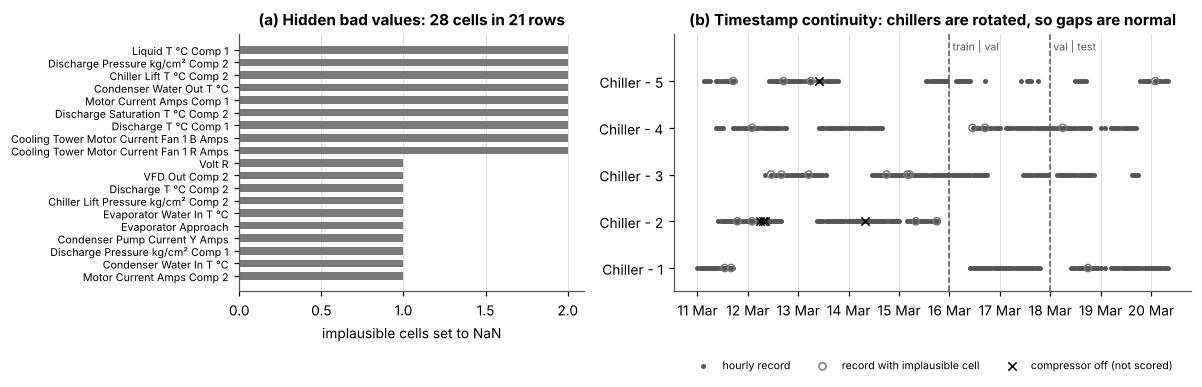

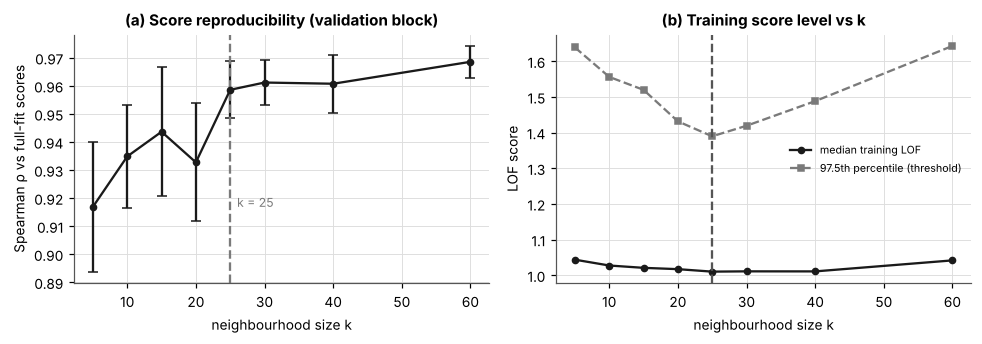

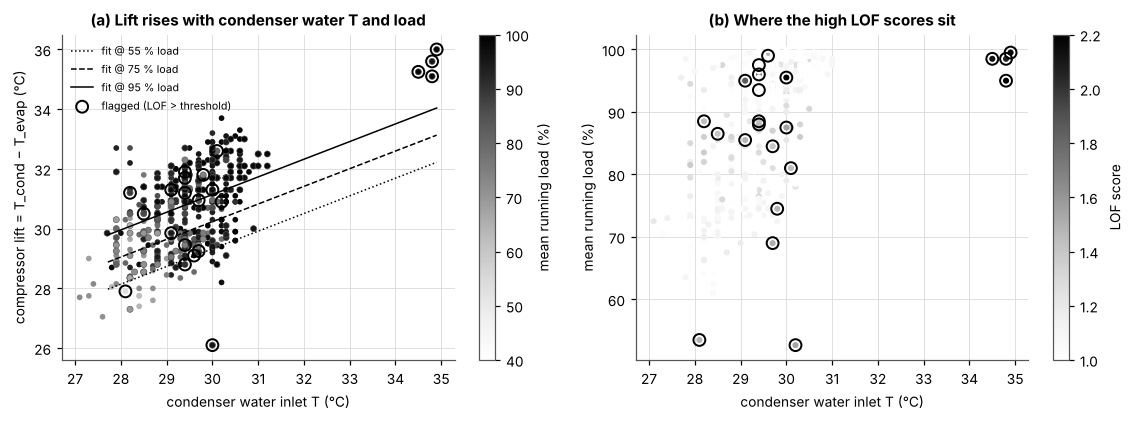

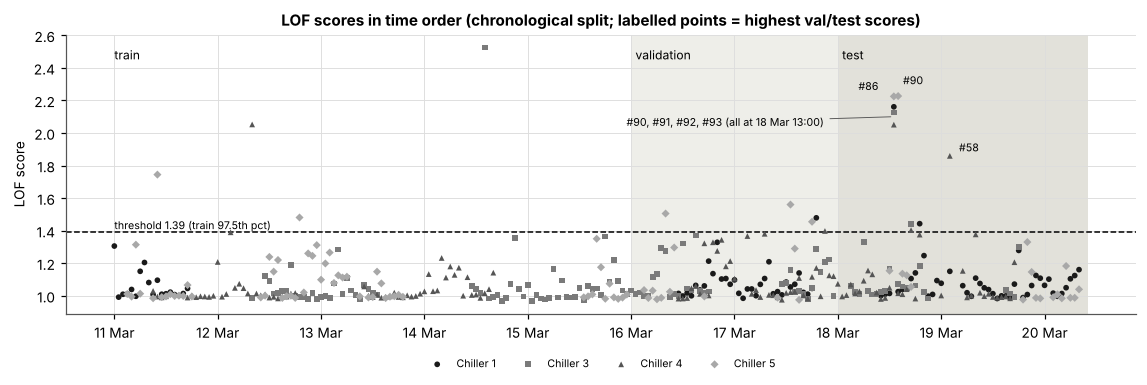

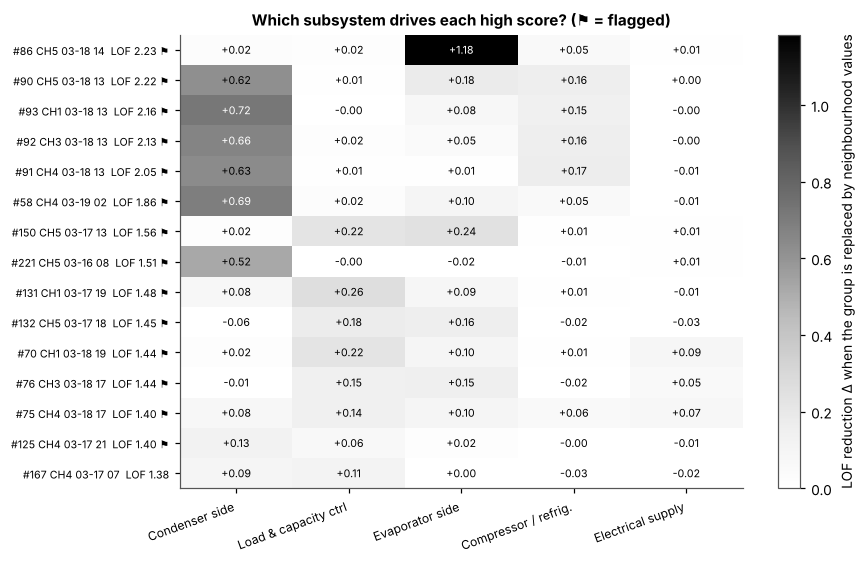

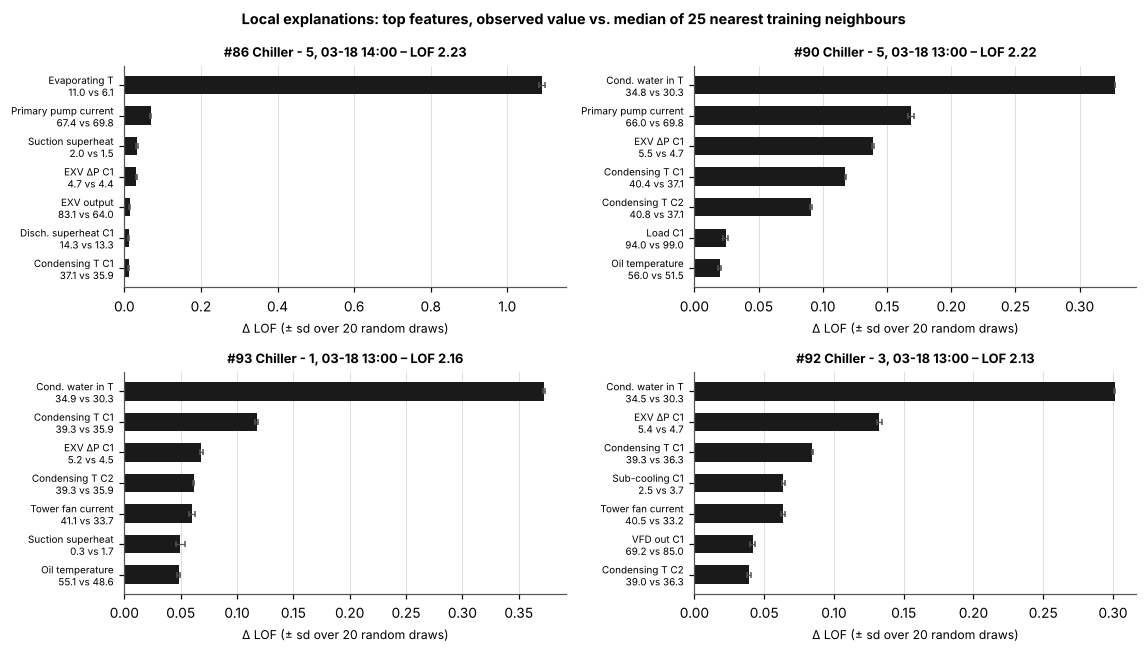

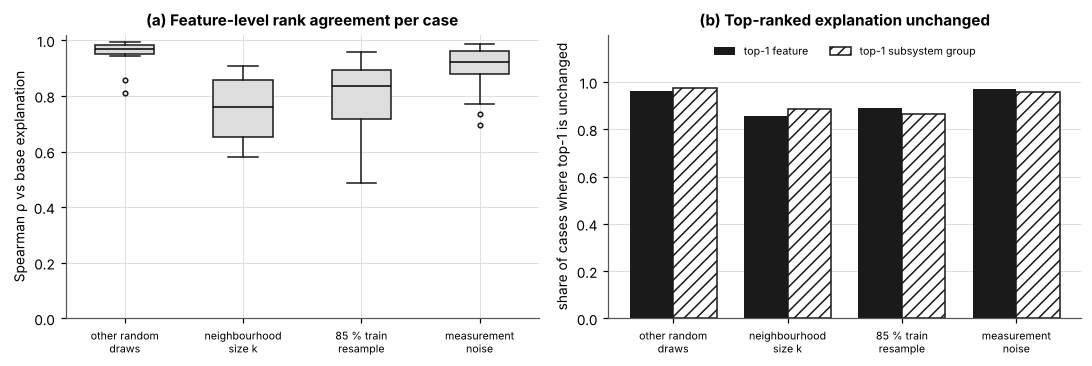

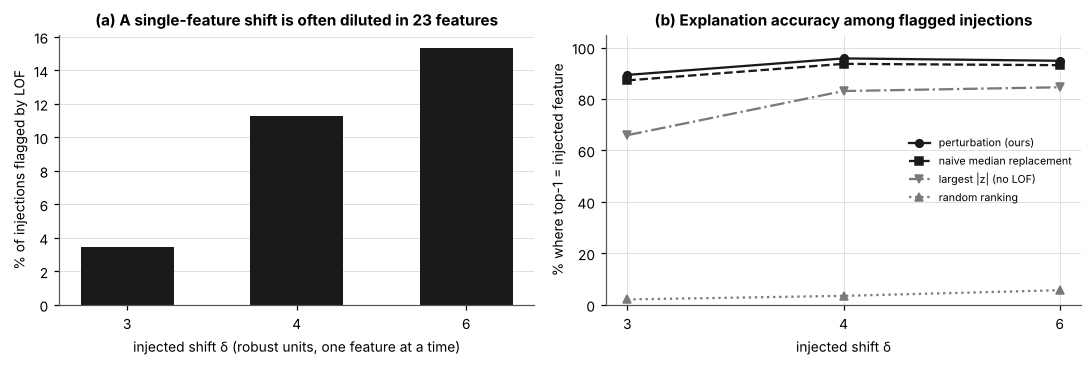

In [19]:
# Fig 1 – data quality: invalid cells per variable, and record availability / continuity per chiller
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
cnt = inval.groupby("variable").size().sort_values()
nice = {v: long_names[v].replace("Deg C", "°C").replace("Kg /cm 2", "kg/cm²").replace("Temperature", "T").replace("Chiler", "Chiller") for v in cnt.index}
ax[0].barh([nice[v] for v in cnt.index], cnt.values, color=C["orange"], height=.6); ax[0].set_xlabel("implausible cells set to NaN"); ax[0].set_title("(a) Hidden bad values: 28 cells in 21 rows"); ax[0].tick_params(axis="y", labelsize=7); ax[0].grid(axis="y", visible=False)
tags = sorted(raw.tag.unique()); ypos = {t: n for n, t in enumerate(tags)}
ax[1].scatter(raw.ts, raw.tag.map(ypos), s=5, color=C["mute"], label="hourly record")
bad_rows = raw.sl.isin(inval.sl); ax[1].scatter(raw.ts[bad_rows], raw.tag[bad_rows].map(ypos), s=22, facecolor="none", edgecolor=C["orange"], lw=1, label="record with implausible cell")
ax[1].scatter(raw.ts[comp_off], raw.tag[comp_off].map(ypos), s=30, marker="x", color=C["ink"], lw=1, label="compressor off (not scored)")
for t_, nm in ((TRAIN_END, "train | val"), (VAL_END, "val | test")): ax[1].axvline(t_, color=C["mute"], ls="--", lw=1); ax[1].text(t_, 4.6, " " + nm, fontsize=7, color=C["mute"], va="bottom")
ax[1].set_yticks(range(5)); ax[1].set_yticklabels(tags); ax[1].set_ylim(-.5, 5.0); ax[1].set_title("(b) Timestamp continuity: chillers are rotated, so gaps are normal"); ax[1].legend(loc="lower center", bbox_to_anchor=(.5, -.35), ncol=3, fontsize=7)
ax[1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%d %b")); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); savefig("fig1_data_quality.png")

# Fig 2 – neighbourhood selection
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].errorbar(ksel.k, ksel.stability_mean, ksel.stability_sd, color=C["blue"], marker="o", ms=4, capsize=3); ax[0].axvline(K, color=C["orange"], ls="--"); ax[0].text(K + 1, ksel.stability_mean.min(), f"k = {K}", color=C["orange"], fontsize=8)
ax[0].set_xlabel("neighbourhood size k"); ax[0].set_ylabel("Spearman ρ vs full-fit scores"); ax[0].set_title("(a) Score reproducibility (validation block)")
ax[1].plot(ksel.k, ksel.train_lof_median, color=C["blue"], marker="o", ms=4, label="median training LOF"); ax[1].plot(ksel.k, ksel.train_lof_p975, color=C["orange"], marker="s", ms=4, ls="--", label="97.5th percentile (threshold)")
ax[1].axvline(K, color=C["mute"], ls="--"); ax[1].set_xlabel("neighbourhood size k"); ax[1].set_ylabel("LOF score"); ax[1].set_title("(b) Training score level vs k"); ax[1].legend(fontsize=7)
plt.tight_layout(); savefig("fig2_k_selection.png")

# Fig 3 – case study plane
m = scores[model_mask].copy(); m["cond_in"] = F.cond_in; m["lift"] = (F.dis_sat1 + F.dis_sat2) / 2 - F.suc_sat
b_l, _ = ols(CS["train"], "lift")
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
sc = ax[0].scatter(m.cond_in[m.split == "train"], m.lift[m.split == "train"], c=m.load_mean[m.split == "train"], cmap="Greys", s=14, vmin=40, vmax=100, edgecolor="none")
ho = m[m.split != "train"]; ax[0].scatter(ho.cond_in, ho.lift, c=ho.load_mean, cmap="Greys", s=16, vmin=40, vmax=100, edgecolor=C["mute"], lw=.4)
xs = np.linspace(m.cond_in.quantile(.01), m.cond_in.max(), 20)
for L, ls in ((55, ":"), (75, "--"), (95, "-")): ax[0].plot(xs, b_l[0] + b_l[1] * xs + b_l[2] * L / 10, color=C["ink"], ls=ls, lw=1, label=f"fit @ {L} % load")
fl = m[m.flag]; ax[0].scatter(fl.cond_in, fl.lift, s=60, facecolor="none", edgecolor="black", lw=1.3, label="flagged (LOF > threshold)")
ax[0].set_xlabel("condenser water inlet T (°C)"); ax[0].set_ylabel("compressor lift = T_cond − T_evap (°C)"); ax[0].set_title("(a) Lift rises with condenser water T and load"); ax[0].legend(fontsize=7, loc="upper left"); plt.colorbar(sc, ax=ax[0], label="mean running load (%)")
sc2 = ax[1].scatter(m.cond_in, m.load_mean, c=m.lof, cmap="Greys", s=16, vmin=1, vmax=2.2, edgecolor="none"); ax[1].scatter(fl.cond_in, fl.load_mean, s=60, facecolor="none", edgecolor="black", lw=1.3)
ax[1].set_xlabel("condenser water inlet T (°C)"); ax[1].set_ylabel("mean running load (%)"); ax[1].set_title("(b) Where the high LOF scores sit"); plt.colorbar(sc2, ax=ax[1], label="LOF score")
plt.tight_layout(); savefig("fig3_case_study.png")

# Fig 4 – LOF over time
fig, ax = plt.subplots(figsize=(10.5, 3.6)); pal = dict(zip(tags[:1] + tags[2:], [(C["blue"], "o"), (C["orange"], "s"), (C["mute"], "^"), (C["aqua"], "D")]))
for t_, (col, mk) in pal.items():
    s_ = scores[model_mask & (scores.tag == t_)]; ax.scatter(s_.ts, s_.lof, s=14, color=col, marker=mk, label=t_.replace("Chiller - ", "Chiller "), edgecolor="none", zorder=3)
ax.axhline(THR, color=C["ink"], ls="--", lw=1); ax.text(scores.ts.min(), THR + .02, f"threshold {THR:.2f} (train 97.5th pct)", fontsize=7)
ax.axvspan(TRAIN_END, VAL_END, color="#eeeee9", lw=0, zorder=0); ax.axvspan(VAL_END, scores.ts.max() + pd.Timedelta(hours=2), color="#e2e1da", lw=0, zorder=0)
ax.text(TRAIN_END + pd.Timedelta(hours=1), ax.get_ylim()[1] * .97, "validation", fontsize=8, va="top"); ax.text(VAL_END + pd.Timedelta(hours=1), ax.get_ylim()[1] * .97, "test", fontsize=8, va="top"); ax.text(scores.ts.min(), ax.get_ylim()[1] * .97, "train", fontsize=8, va="top")
for i, off in zip([cases[0], cases[1], cases[5]], [(-26, 4), (6, 8), (6, 3)]): ax.annotate(f"#{meta.sl[i]}", (meta.ts[i], scores.lof[i]), xytext=off, textcoords="offset points", fontsize=7)
ax.annotate("#90, #91, #92, #93 (all at 18 Mar 13:00)", (pd.Timestamp("2026-03-18 13:00"), 2.1), xytext=(-175, -6), textcoords="offset points", fontsize=7, arrowprops=dict(arrowstyle="-", color=C["mute"], lw=.6))
ax.set_ylabel("LOF score"); ax.set_title("LOF scores in time order (chronological split; labelled points = highest val/test scores)"); ax.legend(ncol=4, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.12)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%d %b"))
plt.tight_layout(); savefig("fig4_lof_timeline.png")

# Fig 5 – group-level attribution heatmap + mean
G = np.array([base_expl[i]["grp"] for i in cases]); lab = [f"#{meta.sl[i]} {meta.tag[i].replace('Chiller - ','CH')} {str(meta.ts[i])[5:13]}  LOF {scores.lof[i]:.2f}" + (" ⚑" if scores.flag[i] else "") for i in cases]
fig, ax = plt.subplots(figsize=(8.2, 5.2)); im = ax.imshow(np.clip(G, 0, None), cmap="Greys", aspect="auto"); ax.set_xticks(range(len(GNAMES))); ax.set_xticklabels(GNAMES, rotation=20, ha="right", fontsize=8); ax.set_yticks(range(len(cases))); ax.set_yticklabels(lab, fontsize=7); ax.grid(False)
for r_ in range(G.shape[0]):
    for c_ in range(G.shape[1]): ax.text(c_, r_, f"{G[r_, c_]:+.2f}", ha="center", va="center", fontsize=7, color="white" if G[r_, c_] > .55 * G.max() else C["ink"])
plt.colorbar(im, label="LOF reduction Δ when the group is replaced by neighbourhood values"); ax.set_title("Which subsystem drives each high score? (⚑ = flagged)"); plt.tight_layout(); savefig("fig5_group_attribution.png")

# Fig 6 – local feature attributions for the four highest cases
fig, axs = plt.subplots(2, 2, figsize=(10.5, 6))
for ax, i in zip(axs.ravel(), cases[:4]):
    e = base_expl[i]; o = top(e["feat"], 7)[::-1]; med = nb_median(i)
    ax.barh([f"{LABELS[FEATS[j]]}\n{F.loc[i, FEATS[j]]:.1f} vs {med[FEATS[j]]:.1f}" for j in o], e["feat"][o], xerr=seed_sd[i][o], color=C["blue"], height=.6, error_kw=dict(ecolor=C["mute"], lw=.8, capsize=2))
    ax.tick_params(axis="y", labelsize=6.5); ax.set_title(f"#{meta.sl[i]} {meta.tag[i]}, {str(meta.ts[i])[5:16]} – LOF {e['s0']:.2f}", fontsize=8.5); ax.set_xlabel("Δ LOF (± sd over 20 random draws)", fontsize=8); ax.grid(axis="y", visible=False)
plt.suptitle("Local explanations: top features, observed value vs. median of 25 nearest training neighbours", fontsize=9.5, fontweight="bold"); plt.tight_layout(); savefig("fig6_local_features.png")

# Fig 7 – explanation stability
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); kinds = sorted(stab.kind.unique()); pc = stab.groupby(["kind", "case"])[["rho", "grp_top1"]].mean().reset_index()
bp = ax[0].boxplot([pc[pc.kind == k_].rho for k_ in kinds], vert=True, widths=.5, patch_artist=True, medianprops=dict(color=C["ink"]), boxprops=dict(facecolor="#dddddd", edgecolor=C["blue"]), whiskerprops=dict(color=C["blue"]), capprops=dict(color=C["blue"]), flierprops=dict(marker="o", ms=3, markeredgecolor=C["blue"]))
ax[0].set_xticks(range(1, 5)); ax[0].set_xticklabels([k_.split(") ")[1].replace("training ", "train\n").replace("neighbourhood ", "neighbourhood\n").replace("random ", "random\n").replace("measurement ", "measurement\n") for k_ in kinds], fontsize=7); ax[0].set_ylabel("Spearman ρ vs base explanation"); ax[0].set_ylim(0, 1.02); ax[0].set_title("(a) Feature-level rank agreement per case")
w = .38; xx = np.arange(4); ax[1].bar(xx - w / 2, [stab_summary.loc[k_, "top-1 feature agrees"] for k_ in kinds], w, color=C["blue"], label="top-1 feature"); ax[1].bar(xx + w / 2, [stab_summary.loc[k_, "top-1 group agrees"] for k_ in kinds], w, color="white", edgecolor=C["blue"], hatch="///", label="top-1 subsystem group")
ax[1].set_xticks(xx); ax[1].set_xticklabels([k_.split(") ")[1].replace("training ", "train\n").replace("neighbourhood ", "neighbourhood\n").replace("random ", "random\n").replace("measurement ", "measurement\n") for k_ in kinds], fontsize=7); ax[1].set_ylim(0, 1.2); ax[1].set_yticks([0, .2, .4, .6, .8, 1]); ax[1].set_ylabel("share of cases where top-1 is unchanged"); ax[1].set_title("(b) Top-ranked explanation unchanged"); ax[1].legend(fontsize=7, loc="upper center", ncol=2); ax[1].grid(axis="x", visible=False)
plt.tight_layout(); savefig("fig7_explanation_stability.png")

# Fig 8 – injection test
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); dd = inj_by_delta.loc[[3, 4, 6]]; cols = dict(zip(meths, [C["blue"], C["blue"], C["orange"], C["orange"]]))
ax[0].bar(dd.index.astype(str), dd.detection_rate * 100, color=C["blue"], width=.55); ax[0].set_xlabel("injected shift δ (robust units, one feature at a time)"); ax[0].set_ylabel("% of injections flagged by LOF"); ax[0].set_title("(a) A single-feature shift is often diluted in 23 features"); ax[0].grid(axis="x", visible=False)
for n_, m_ in enumerate(meths): ax[1].plot(dd.index.astype(str), dd[m_ + " top-1"] * 100, marker="osv^"[n_], ms=5, ls=["-", "--", "-.", ":"][n_], color=cols[m_], label=m_)
ax[1].set_ylim(0, 105); ax[1].set_xlabel("injected shift δ"); ax[1].set_ylabel("% where top-1 = injected feature"); ax[1].set_title("(b) Explanation accuracy among flagged injections"); ax[1].legend(fontsize=7, loc="center right")
plt.tight_layout(); savefig("fig8_injection_test.png")

## 13. Export: model configuration, metrics, preprocessing notes

In [20]:
config = dict(
    data=dict(file=str(DATA), sheet="Log_Chiller_South", records=int(len(raw)), chillers=int(raw.tag.nunique()), cadence="hourly, per-chiller (rotated duty)"),
    split=dict(type="chronological, whole days", train=["2026-03-11", "2026-03-15"], validation=["2026-03-16", "2026-03-17"], test=["2026-03-18", "2026-03-20"],
               scored_rows={s: int(len(ix[s])) for s in ix}),
    cleaning=dict(range_rules=RANGES, structural_states=["compressor off (running load = 0)", "cooling-tower fan 2 off (all phases 0 A)"], invalid_cells=int(len(inval)),
                  load_current_A_per_pct={str(k): round(v, 4) for k, v in apl.items()}),
    imputation=dict(step1="causal forward fill within chiller, max 3 h", step2="training median per chiller, then global training median", cells_imputed_scored_rows=int(isna_mask[model_mask].sum().sum())),
    features=dict(candidates=feat_cols, dropped_redundant={k: list(v) for k, v in dropped.items()}, used=FEATS, groups=GROUPS),
    scaling=dict(name="RobustScaler (median/IQR)", fit_on="training block only"),
    model=dict(name="LocalOutlierFactor", n_neighbors=K, novelty=True, metric="minkowski p=2 (Euclidean)", threshold=round(THR, 4), threshold_rule="97.5th percentile of training LOF scores", k_grid=K_GRID,
               k_rule="smallest k with >=97% of best bootstrap rank-stability and k >= d+1"),
    explainer=dict(name="local feature perturbation", replacement="value of a random one of the k nearest training neighbours", draws_R=50, neighbours=K, group_level=True, baseline="global training median"),
    evaluation=dict(stability_perturbations=["20 random-draw seeds", "k_LOF in {10,15,40,60} and k_neighbourhood in {10,40,60}", "20 x 85% training resamples (scaler+LOF refit)", "20 x Gaussian noise sd 0.05 robust units"],
                    n_cases=len(cases), injection=dict(shifts_robust_units=[2, 3, 4, 6], clip="training [p0.5,p99.5]", draws_R=30, test_inliers_used=len(sel))),
    seed=SEED)
json.dump(config, open(OUT/"model_config.json", "w"), indent=2, default=str)

metrics = dict(
    lof_by_split={s: dict(n=int(summ.loc[s, "n"]), median=float(summ.loc[s, "median_lof"]), max=float(summ.loc[s, "max_lof"]), flagged=int(summ.loc[s, "flagged"])) for s in ("train", "val", "test")},
    k=K, threshold=THR, k_selection_stability=float(ksel.set_index("k").loc[K, "stability_mean"]),
    case_study=case_tbl.round(4).to_dict(orient="records"), event_18mar_1300=event.round(3).to_dict(),
    explanation_stability=stab_summary.round(4).to_dict(orient="index"), sufficiency=suff_metrics,
    plausibility_flag_rate_pct={k_: round(100 * v, 2) for k_, v in plaus.items()},
    injection=dict(n_injections=int(len(inj)), n_detected=int(len(det)), detection_rate=float(len(det) / len(inj)), accuracy_detected=inj_tbl.round(4).to_dict(orient="index"), by_delta=inj_by_delta.round(4).to_dict(orient="index")),
    data_quality=dict(invalid_cells=int(len(inval)), rows_with_invalid=int(inval.sl.nunique()), compressor_off_rows=int(comp_off.sum()), imputed_cells_scored=int(isna_mask[model_mask].sum().sum())))
json.dump(metrics, open(OUT/"metrics.json", "w"), indent=2, default=str)
scores[model_mask][["sl", "tag", "ts", "split", "lof", "flag", "n_imputed"]].sort_values("lof", ascending=False).to_csv(OUT/"tables"/"lof_scores_all.csv", index=False)

notes = f"""# Preprocessing notes – chiller operating log

**Source.** `{DATA.name}`, sheet *Log_Chiller_South*: {len(raw)} hourly log records, 5 chillers (2 compressors each), 11–20 Mar 2026, 60 columns. Two title rows precede the header; the row order is descending in time.

## 1. Structure and timestamps
* `Date` + `Time` combined into one timestamp; records sorted ascending. No duplicated (chiller, timestamp) pairs.
* Records are hourly *within* a chiller, but chillers are rotated on and off duty, so each chiller has gaps (longest gap {continuity.longest_gap_h.max():.0f} h, Chiller 1). Gaps are an operating pattern, not missing sensor data, and the gaps are never interpolated across.
* The log does not form one regular time series per chiller, so no sequence model was used; LOF operates on single records.

## 2. Units and derived columns
* Temperatures °C, compressor pressures kg/cm², pump pressures bar (mixed units, not converted because pump pressures are not model inputs), currents A, voltage V.
* Many logged columns are differences of others (they hold on most rows) (lift T = discharge T – suction T, lift P, condenser approach = discharge sat. T – condenser outlet, evaporator approach, both superheats) and **running load % = motor current / full-load amps** (2.25 A per % for compressor 1, 2.15 for compressor 2). They add no information and were not used as model inputs.
* Run-hour counters are cumulative meters, with several decreases/jumps (e.g. 1179 or 40715 against ~11 500), so they were audited and excluded.

## 3. Cleaning decisions (rule based; nothing fitted)
| Decision | Rule | Effect |
|---|---|---|
| Implausible value → NaN | engineering range per variable (table in `model_config.json`) | {len(inval)} cells in {inval.sl.nunique()} rows, e.g. 2196 A, 631 °C, 40.8 V, 85 °C |
| Compressor off | running load = 0 % | {int(comp_off.sum())} rows kept as a separate operating state and **not scored** (their own variables are legitimately 0) |
| Tower fan 2 off | all three phase currents = 0 | {int(fan2_off.sum())} rows, valid state, not treated as errors |
| Load/current mismatch | load differs from current/(A per %) by > 8 points | load rebuilt from current in {n_fix} cells |
| Condenser pump pressures | 0.0 on ~5 % of rows with normal pump current | excluded from features |

## 4. Imputation (training statistics only)
1. Causal forward fill from the same chiller's previous record when ≤ 3 h old.
2. Otherwise the training-block median of that chiller, then the global training median.
Only {int(isna_mask[model_mask].sum().sum())} cells ({isna_mask[model_mask].values.mean()*100:.2f} % of scored cells, {int((meta.n_imputed[model_mask] > 0).sum())} rows) needed imputation. None of the top-15 cases contains an imputed value.

## 5. Features, pruning and scaling
* {len(feat_cols)} candidate features from independent measurements/differences in five subsystem groups; pruning at training |Spearman| > 0.90 dropped {', '.join(dropped) or 'nothing'} → **{len(FEATS)} model features**.
* `RobustScaler` (median/IQR) fitted on the training block.
* No dimensionality reduction (PCA would make explanations unreadable).

## 6. Chronological split and leakage control
Train 11–15 Mar ({len(ix['train'])} scored rows), validation 16–17 Mar ({len(ix['val'])}), test 18–20 Mar ({len(ix['test'])}). Imputation medians, pruning, scaling, the A-per-% constant, the LOF fit and the alert threshold use training rows only; the validation block was used only to choose k; the test block was scored once. For the synthetic-injection check the anomalies were injected into a separate copy of the test inliers while the clean reference data stayed unchanged.

## 7. Known limitations
No kW or flow data (efficiency is judged through lift/ideal-COP proxies); no fault labels; only 10 days of data; chillers are pooled; one-hour duty events and shared sensors create near-duplicate records.
"""
(OUT/"preprocessing_notes.md").write_text(notes); print(notes[:600])

# Preprocessing notes – chiller operating log

**Source.** `Analyse_Chillers_AI_Course.xls`, sheet *Log_Chiller_South*: 522 hourly log records, 5 chillers (2 compressors each), 11–20 Mar 2026, 60 columns. Two title rows precede the header; the row order is descending in time.

## 1. Structure and timestamps
* `Date` + `Time` combined into one timestamp; records sorted ascending. No duplicated (chiller, timestamp) pairs.
* Records are hourly *within* a chiller, but chillers are rotated on and off duty, so each chiller has gaps (longest gap 113 h, Chiller 1). Gaps are an operating pattern, not m


## 14. Findings and interpretation
*(Numbers below are those printed above; the random seed is fixed so a re-run reproduces them.)*

**Data quality.** 522 records, no blank cells, but 28 implausible values in 21 records (typing slips such as 2196 A, 631 °C, 40.8 V), 5 compressor-off records, and cumulative run-hour counters that jump.
After cleaning only 11 cells (0.09 %) needed imputation. Load % is a rescaled motor current, and ten further columns are differences of others, so the model uses 23 independent features.

**Model.** LOF with k = 25 (bootstrap rank-stability ρ ≈ 0.96) and a threshold of 1.39. Flag rate: 2.8 % of train, 4.3 % of validation, **7.5 % of test (9 of 120)** – the test block contains conditions that the training block did not (see below).

**Case study – condenser temperature and load vs efficiency proxies (training fit, later days used for checking).**
* +1 °C condenser water inlet temperature → **+0.59 °C compressor lift** (95 % bootstrap CI 0.35–0.81), i.e. about −1.8 % ideal COP.
* +10 % running load → **+0.45 °C lift** (0.31–0.63), about −1.5 % ideal COP.  Out-of-sample R² 0.49 (lift) / 0.41 (ideal COP).
* Condenser water temperature and load are themselves correlated (ρ = 0.67), so the two effects are not cleanly separable in 10 days of data; these are proxies, not measured kW/TR.

**Local case review (15 highest val/test scores).**
* **18 Mar 13:00 – four ranks at once (#90, #91, #92, #93).** All four running chillers show condenser water inlet 34.5–34.9 °C against a neighbourhood median of 30.3 °C (training maximum 30.8 °C). Every explanation puts the condenser side first (Δ = +0.62 to +0.72) and the top feature is condenser water inlet temperature.
  Compared with the previous hour on the same chillers: condensing temperature +3.4 °C, lift +3.9 °C (the linear case-study fit predicts +2.6 °C, i.e. extrapolation beyond the training range), ideal COP −11 %, tower-fan current +24 %. The logged approach/superheat identities are consistent, and the next hour is back to ≈ 30 °C.
  Four independent machines moving together points to a *plant-level* cause (cooling-tower / condenser-water loop, a shared sensor or a logging issue) rather than four chiller faults – but this log cannot tell which.
* **#86 (CH5, 18 Mar 14:00).** One feature explains almost everything: evaporating temperature 11.0 °C vs 6.1 °C (Δ = +1.09; every other feature < 0.07). An identity check that was *not* used in training shows the logged evaporator approach and suction superheat are both off by 6.0 K, and 11.0 °C is above the chilled-water outlet temperature (8.3 °C) – physically implausible. This looks like a recording error, a data-quality finding rather than a plant event.
* **#58 (CH4, 19 Mar 02:00) and #221 (CH5, 16 Mar 08:00).** Condenser water temperature rise of 1.4 K and 0.4 K against ≈ 2.2–2.6 K in comparable states. Possible causes include higher-than-normal condenser water flow or a sensor offset; independent evidence is needed.
* **#131, #132, #70, #76, #75 (rank 9–13).** Low-scoring flags driven by unequal compressor loads (e.g. 52 % vs 86 %) and slightly low supply voltage (404 V); consistent with load sharing/sequencing, probably benign.

**Explanations – evaluation.**
* *Stability:* same observation, new random draws: ρ = 0.95, top-1 feature unchanged in 96 %; with 0.05-unit noise: ρ = 0.90 (97 %); different k: ρ = 0.75 (86 %); 85 % training resamples: ρ = 0.78 (89 %). The **top-1 subsystem group** is more stable (86–97 %) than the full feature ranking – the *dominant* reason is reliable, the order of weak contributors is not.
* *Sufficiency:* replacing the top-ranked group with neighbourhood values brings 10 of 14 flagged points (71 %) below the threshold, against 21 % for a randomly chosen group; it removes a median 52 % of the excess score.
* *Plausibility:* perturbing normal points with neighbourhood values makes 0.4 % of them look anomalous, vs 1.2 % (global median), 2.4 % (random training value), 4.3 % (uniform range).
* *Injection test (clean test copy):* LOF only flags 3 %, 11 % and 15 % of single-feature shifts of 3, 4 and 6 robust units (one shift in 23 features is diluted). Among the 366 flagged injections the explainer's top-1 feature is the injected one in **94 %** (95 % CI ± 2.4), the top-3 in 98 %, the correct group in 97 %. The naive median-replacement explainer reaches 92 % and a plain largest-|z| ranking 81 %; random ranking 4 %.
  Over *all* injections (flagged or not) the figures are 71 %, 64 % and 53 %. The advantage over naive replacement is small (about 2 points on flagged, 7 points on all injections). With one injected feature at a time this is the easy case, so the result shows the explainer is sound, not that it will always find real faults.

**Answer to the research question.** Yes, to a useful but bounded extent. Local perturbation explanations identify the dominant feature or subsystem behind a high LOF score reliably (≈ 90–97 % agreement across re-draws, noise and training resamples) and the neighbourhood comparison makes the reason readable ("34.8 °C vs 30.3 °C in similar states").
They also turned one high score (#86) into an actionable data-quality finding and another (#90–#93) into evidence for a plant-level event. They do **not** establish a cause or a fault: ranks of the minor contributors change with k and with the training sample, and both the 18 Mar event and the #86 reading need independent confirmation.

**Limitations.** No power/flow readings (efficiency by proxy), no fault labels (so no precision/recall), 10 days of data, only 282 training rows for a 23-dimensional space, near-duplicate neighbours from hourly records, pooled chillers, and a single synthetic-injection design (single-feature shifts). The k-selection used validation-block stability only.